# Ammonia/Hydrogen Kinetics: Active Subspaces of Ignition Delay and Flame Speed in 52 Uncertain Rate Constants

__Gongrui Huang__, School of Engineering and Design, Technical University of Munich, 85748 Garching, Germany

__Hongxin Wang__, School of Engineering and Design, Technical University of Munich, 85748 Garching, Germany

__Liang Tian__, School of Energy and Environmental Engineering, Hebei University of Technology, 300401 Tianjin, China

__Oskar Haidn__, School of Engineering and Design, Technical University of Munich, 85748 Garching, Germany

__Nadezda Slavinskaya__, School of Engineering and Design, Technical University of Munich, 85748 Garching, Germany

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1.0 or later) and reads the shipped data files. In the repository's terms this is a **stored-data** set: the data were computed for this repository with [Cantera](https://cantera.org) 3.2.0, an outside code, driven by `nh3h2_kinetics_driver.py`, using the authors' NH$_3$/H$_2$ mechanism from the paper's supplement. The mechanism file is not distributed here (its header restricts copying and distribution); `generate_data.py` and `check_accuracy.py` need Cantera and that file, and `DATA.md` says how to get both. The notebook itself needs neither: it imports only the driver's constants (names, bounds, labels).

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import nh3h2_kinetics_driver as D   # names, bounds and labels (numpy only); solving needs Cantera and the mechanism

SEED = 470                           # the only seed in this notebook (bootstrap, the log-uniform check and the reduced-box sample)
t_start = time.perf_counter()
LAB = [D.label(i) for i in range(D.M_INPUTS)]   # Table 4 names (R1..R23, R9L/H, R22L/H); S<row> for the others

### Summary

Huang et al. [1] quantify and reduce the uncertainty of a new NH$_3$/H$_2$ combustion mechanism (42 species, 346 reactions) by Latin hypercube sampling of the pre-exponential factors of 52 highly sensitive reactions within their initial uncertainty bounds. We rerun the authors' mechanism in Cantera at one shock-tube ignition condition and one laminar flame of the paper's Fig. 10, compute gradients with respect to the 52 log$_{10}$ factors, and estimate active subspaces from Latin hypercubes of 1000 (ignition delay $\tau$) and 200 (flame speed $S_u$) samples. The flame speed has a clear one-dimensional active subspace led by H + O$_2$ ⇌ O + OH ($\lambda_1/\lambda_2 = 10.22$; a quadratic in $y_1$ has leave-one-out $R^2$ = 0.9332), while $\log_{10}\tau$ has one well-determined direction ($\lambda_1/\lambda_2 = 6.14$) that leaves about a quarter of the variance (leave-one-out $R^2$ = 0.7376) spread over many NH$_x$/NO reactions.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs, normalized to $\mathbf x\in[-1,1]^m$ with the uniform density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend and a low-degree polynomial in $\mathbf y$ can stand in for $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

**Rate constants.** Every reaction rate constant has the modified Arrhenius form [1, Eq. 2, p. 2]
$$k(T) = A\,T^{n}\exp\!\left(-\frac{E_a}{T}\right)\qquad(E_a \text{ in K}).$$
The mechanism is the authors' (42 species, 346 reactions [1, p. 5]), the Cantera file `NH3_H2.yaml` of the supplement, used unchanged.

**Inputs.** The paper samples "the pre-exponential factor (A) of 52 highly sensitive reactions [...] within their initial uncertainty bounds" by Latin hypercube [1, Sec. 3.4, p. 9], counting the low- and high-pressure limits of falloff reactions separately [1, p. 5]. The bounds are factors on $k$ [1, Eqs. 5–6, p. 3], $f_l = \log_{10}(k_0/k_{low})$ and $f_u = \log_{10}(k_{up}/k_0)$, with $f_l^{ini} = f_u^{ini} = f^{ini}$ for the initial bounds (Table 4 heading, p. 7). Our inputs are
$$x_i = \log_{10}\frac{A_i}{A_{i,0}},\qquad x_i \sim \mathcal U[-f^{ini}_i,\ f^{ini}_i],\quad i = 1,\dots,52,$$
independent, where $A_{i,0}$ is the value in the mechanism file; changing $A_i$ multiplies $k_i$ by $10^{x_i}$ at every temperature, and for a falloff entry only the named limit changes. The paper says $A$ was "randomly and uniformly sampled within [its] initial bounds" [1, p. 3] without naming the scale. Sampling uniformly in $\log_{10}A$ is this data set's choice, and the paper's reduced bounds support it strongly. They are $A_{ave} \pm 0.5\sigma_A$ of the filtered samples [1, p. 10], with the statistics taken in $\log_{10}A$ (Fig. 9, p. 10; R1's bounds 13.897 and 14.216). For a log-uniform distribution that the filtering leaves unchanged, $\pm 0.5\sigma$ spans $1/(2\sqrt3) = 0.2887$ of the initial width, centred on the nominal value. The printout below the table shows that 41 of the 52 reduced widths lie between 0.2800 and 0.2881 of the initial width and that every reduced interval is centred on the nominal value to within 0.049 $f^{ini}$, whereas sampling uniform in $A$ itself would centre the $\log_{10}A$ statistics 0.22 $f^{ini}$ (smallest $f^{ini}$) to 0.83 $f^{ini}$ (largest) above the nominal value, with width ratios 0.276 to 0.087. The table below is printed from the driver: the 52 entries of the supplement's table (`mmc1.xlsx`), with the paper's Table 4 labels (p. 7) for the 25 entries it lists and S&lt;row&gt; for the others, the $A_0$ printed in the table (cm, mol, s), the initial factor and the paper's reduced factors $f^{red}_l, f^{red}_u$.

**Quantity of interest 1: ignition delay.** An adiabatic, constant-volume reactor (density $\rho$ fixed), with mass fractions $Y_k$, molar production rates $\dot\omega_k$, molar masses $W_k$, molar internal energies $u_k$ and specific heat $c_v$:
$$\frac{dY_k}{dt} = \frac{W_k\,\dot\omega_k}{\rho},\qquad \frac{dT}{dt} = -\frac{1}{\rho\,c_v}\sum_k u_k\,\dot\omega_k .$$
Initial state: 4.375 % NH$_3$ / 3.281 % O$_2$ / 92.344 % Ar at $T_5$ = 1587.982151 K and $p_5$ = 10 atm, the mixture and pressure of the paper's Fig. 10(b) (p. 11) and the exact state of a Chen et al. [3] shock-tube point in the supplement's data (measured $\tau$ = 0.4 ms). $\tau$ is the first time $T$ reaches $T_5$ + 400 K. The paper states no ignition criterion and applies a pressure-rise correction "where such data were available" (p. 3); the criterion, the absence of a pressure rise and the choice of one temperature are this data set's choices. The criterion does not matter for the subspace: the time of the maximum of $dT/dt$ gives the same gradient direction (`DATA.md`, Accuracy, check 2). We analyze $\log_{10}(\tau/1\,\mathrm{s})$, because $\tau$ spans more than two decades.

**Quantity of interest 2: laminar flame speed.** A freely propagating, steady, one-dimensional premixed flame with mixture-averaged transport; with mass flux $\dot m = \rho u = \rho_u S_u$, diffusive fluxes $j_k$, enthalpies $h_k$ and conductivity $\lambda$,
$$\dot m\frac{dY_k}{dz} = -\frac{dj_k}{dz} + W_k\dot\omega_k,\qquad \dot m\,c_p\frac{dT}{dz} = \frac{d}{dz}\Big(\lambda\frac{dT}{dz}\Big) - \sum_k h_k\dot\omega_k - \sum_k j_k c_{p,k}\frac{dT}{dz},$$
and $S_u$ (cm/s) is the inflow velocity of the unburned gas. Conditions of the paper's Fig. 10(c) (p. 11) at $\phi$ = 1: 50 % NH$_3$ + 50 % H$_2$ (by mole) with air, $T_u$ = 298 K, $p$ = 1 atm. The grid refinement (ratio 3, slope 0.1, curve 0.2) is coarser than the paper's (2, 0.01, 0.02; p. 4), a cost choice of this data set. `DATA.md` (Accuracy) quantifies its effect: the coarser grid gives slightly lower flame speeds, most for the slowest flames, and leaves the direction of the gradient at the nominal point almost unchanged.

In [2]:
print(f"{'input':5s} {'label':5s} {'reaction (supplement table; low/high: falloff limit)':42s} {'A0 (table)':>10s} "
      f"{'f_ini':>6s} {'f_red_l':>7s} {'f_red_u':>7s}  T range (K)")
for i, r in enumerate(D.TABLE):
    print(f'{D.NAMES[i]:5s} {LAB[i]:5s} {r[1]:42s} {r[2]:10.3e} {r[3]:6.3f} {r[4]:7.3f} {r[5]:7.3f}  {r[6]}')
print(f'\nm = {D.M_INPUTS} inputs x_i = log10(A_i/A_i0), uniform on [-f_ini, f_ini]; f_ini from {D.F_INI.min():.3f} '
      f'to {D.F_INI.max():.3f} (factors {10**D.F_INI.min():.1f} to {10**D.F_INI.max():.0f} on A)')
print(f'reduced widths (f_red_l + f_red_u) / (2 f_ini): {np.min((D.F_RED_L + D.F_RED_U) / (2 * D.F_INI)):.3f} '
      f'to {np.max((D.F_RED_L + D.F_RED_U) / (2 * D.F_INI)):.3f}')
r_red = (D.F_RED_L + D.F_RED_U) / (2 * D.F_INI)              # reduced width / initial width
c_red = (D.F_RED_U - D.F_RED_L) / (2 * D.F_INI)              # centre of the reduced interval, in units of f_ini
print(f'{np.sum((r_red >= 0.28) & (r_red < 1 / np.sqrt(12)))} of {D.M_INPUTS} width ratios between 0.2800 and {r_red.max():.4f}; '
      f'1/(2 sqrt 3) = {1 / np.sqrt(12):.4f} (+/- 0.5 sd of a log-uniform distribution); '
      f'largest |centre| of a reduced interval {np.abs(c_red).max():.3f} f_ini ({LAB[int(np.argmax(np.abs(c_red)))]})')
rng_lu = np.random.default_rng(SEED)
for f in (D.F_INI.min(), D.F_INI.max()):
    L = np.log10(rng_lu.uniform(10**-f, 10**f, 200000))      # log10(A/A0) if A were uniform in A
    print(f'if A were uniform in A (f_ini = {f:.3f}): mean of log10(A/A0) = {L.mean() / f:.2f} f_ini, '
          f'+/- 0.5 sd width / initial width = {L.std() / (2 * f):.3f}')


input label reaction (supplement table; low/high: falloff limit) A0 (table)  f_ini f_red_l f_red_u  T range (K)
x01   R1    H + O2 <=> O + OH                           1.040e+14  0.699   0.120   0.188  298 - 3550
x02   S2    H + O2 (+M) <=> HO2 (+M) low                6.366e+20  0.301   0.087   0.085  298 - 3000
x03   S3    H + O2 (+M) <=> HO2 (+M)                    4.651e+12  0.301   0.087   0.086  298 - 3000
x04   R2    H2 + O <=> OH + H                           5.080e+04  0.477   0.138   0.136  298 - 3000
x05   R3    H2 + OH <=> H + H2O                         2.160e+08  0.301   0.087   0.084  298 - 3000
x06   S6    H2O2 (+M) <=> 2 OH (+M) low                 2.490e+24  1.000   0.287   0.285  600 - 3000
x07   S7    H2O2 (+M) <=> 2 OH (+M) high                2.000e+12  1.477   0.423   0.420  600 - 2000
x08   R4    NH3 + H <=> NH2 + H2                        2.890e+06  1.176   0.320   0.338  298 - 3070
x09   R5    NH3 + O <=> NH2 + OH                        2.790e+02  1.301   0.359

### Load data

`generate_data.py` drew one Latin hypercube per quantity (1000 points for the ignition delay, seed 470001; 200 points for the flame speed, seed 470002) on the box above, ran the Cantera model at each point, and wrote the inputs $x_i$, the outputs and their gradients with respect to the $x_i$: forward differences (step $10^{-3}$ in $x_i$) for the ignition delay $\tau$, and Cantera's discrete adjoint for the flame speed $S_u$. `nominal.csv` holds both quantities and gradients at $\mathbf x = 0$. Accuracy checks are in `DATA.md`.

In [3]:
Xi = np.loadtxt('idt_inputs.csv', delimiter=',')       # (1000, 52) x_i = log10(A_i/A_i0)
taui = np.loadtxt('idt_outputs.csv', delimiter=',')    # (1000,) ignition delay tau, s
Gi = np.loadtxt('idt_gradients.csv', delimiter=',')    # (1000, 52) dtau/dx_i, s per log10 unit
Xl = np.loadtxt('lfs_inputs.csv', delimiter=',')       # (200, 52) x_i
Ol = np.loadtxt('lfs_outputs.csv', delimiter=',')      # (200, 3) Su (cm/s), grid points, fresh-start flag
Gl = np.loadtxt('lfs_gradients.csv', delimiter=',')    # (200, 52) dSu/dx_i, cm/s per log10 unit
nom = np.loadtxt('nominal.csv', delimiter=',')         # (2, 53) row 1: tau, dtau/dx; row 2: Su, dSu/dx
for n, a in [('Xi', Xi), ('taui', taui), ('Gi', Gi), ('Xl', Xl), ('Ol', Ol), ('Gl', Gl), ('nom', nom)]:
    print(f'{n:5s} {a.shape}')

Xi    (1000, 52)
taui  (1000,)
Gi    (1000, 52)
Xl    (200, 52)
Ol    (200, 3)
Gl    (200, 52)
nom   (2, 53)


We check the designs (each column of a Latin hypercube has one point in each of the $N$ equal strata), look for failed solves (stored as NaN; such rows would be dropped here, by that rule only), and check the gradient coordinates: the least-squares slope of each quantity on the normalized inputs should point the same way as the mean normalized gradient.

In [4]:
ok_i = np.isfinite(taui) & np.all(np.isfinite(Gi), axis=1)
ok_l = np.isfinite(Ol[:, 0]) & np.all(np.isfinite(Gl), axis=1)
print(f'failed rows: ignition {np.sum(~ok_i)}, flame {np.sum(~ok_l)}; flames restarted from scratch: {int(Ol[:, 2].sum())}')
fI = np.log10(taui[ok_i])                                    # QoI 1: log10(tau / 1 s)
gI = Gi[ok_i] / (taui[ok_i, None] * np.log(10.0))            # d log10(tau) / dx_i
fL, gL = Ol[ok_l, 0], Gl[ok_l]                               # QoI 2: Su (cm/s) and dSu/dx_i
XI, XL = Xi[ok_i], Xl[ok_l]
for name, X, f, g in [('log10 tau', XI, fI, gI), ('Su', XL, fL, gL)]:
    N = len(X)
    Z = X / D.F_INI                                          # normalized inputs in [-1, 1]
    strata = np.floor((Z + 1) / 2 * N).astype(int)
    lhs_ok = all(np.array_equal(np.sort(strata[:, j]), np.arange(N)) for j in range(D.M_INPUTS))
    kurt = np.mean((Z - Z.mean(0))**4, 0) / Z.var(0)**2
    b = np.linalg.lstsq(np.column_stack([np.ones(N), Z]), f, rcond=None)[0][1:]
    gbar = (g * D.F_INI).mean(0)
    print(f'{name:9s}: N = {N}, normalized inputs in [{Z.min():.4f}, {Z.max():.4f}], one point per stratum in every '
          f'column: {lhs_ok}, kurtosis {kurt.min():.2f}-{kurt.max():.2f} (uniform 1.8)')
    print(f'           OLS slope vs mean normalized gradient: cosine {b @ gbar / np.linalg.norm(b) / np.linalg.norm(gbar):.3f}')
q = np.percentile(taui[ok_i], [0, 5, 50, 95, 100]) * 1e3
print(f'tau (ms): min {q[0]:.4f}, 5 % {q[1]:.4f}, median {q[2]:.4f}, 95 % {q[3]:.3f}, max {q[4]:.3f}; '
      f'nominal {nom[0, 0] * 1e3:.4f} ms; log10 range {np.ptp(fI):.2f} decades')
q = np.percentile(fL, [0, 5, 50, 95, 100])
print(f'Su (cm/s): min {q[0]:.2f}, 5 % {q[1]:.2f}, median {q[2]:.2f}, 95 % {q[3]:.2f}, max {q[4]:.2f}; '
      f'nominal {nom[1, 0]:.2f} cm/s; grid points {int(Ol[:, 1].min())}-{int(Ol[:, 1].max())}')

failed rows: ignition 0, flame 0; flames restarted from scratch: 0
log10 tau: N = 1000, normalized inputs in [-1.0000, 0.9999], one point per stratum in every column: True, kurtosis 1.80-1.80 (uniform 1.8)
           OLS slope vs mean normalized gradient: cosine 0.988
Su       : N = 200, normalized inputs in [-0.9999, 1.0000], one point per stratum in every column: True, kurtosis 1.80-1.80 (uniform 1.8)
           OLS slope vs mean normalized gradient: cosine 0.979
tau (ms): min 0.0555, 5 % 0.1801, median 0.7497, 95 % 3.368, max 10.634; nominal 0.6907 ms; log10 range 2.28 decades
Su (cm/s): min 4.41, 5 % 10.79, median 33.59, 95 % 83.18, max 125.98; nominal 40.69 cm/s; grid points 113-179


All 1000 ignition runs and 200 flames succeeded (no NaN rows, so no row is dropped), and no flame had to be solved from scratch. Both designs are Latin hypercubes as stored: in every column each of the $N$ strata holds exactly one point, and the normalized inputs have kurtosis 1.80 (uniform). Every input is physically meaningful (each factor $10^{x_i}$ is positive). The least-squares slope and the mean normalized gradient point the same way (cosine 0.988 for $\log_{10}\tau$ and 0.979 for $S_u$), which confirms the gradient coordinates. The ignition delay spans 2.28 decades, from 0.0555 to 10.634 ms (median 0.7497 ms; nominal model 0.6907 ms). The flame speed runs from 4.41 to 125.98 cm/s (median 33.59 cm/s; nominal 40.69 cm/s), on grids of 113–179 points.

### Estimate the subspace

Every sample has a gradient (forward differences for $\tau$, Cantera's discrete adjoint for $S_u$; their accuracy is checked in `DATA.md`), so we use the gradient estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i\nabla f_i\nabla f_i^T$. All inputs are uniform, and `ac.Uniform(lower, upper)` scales every input by its own half-range $f^{ini}_i$ onto $[-1,1]$ (for uniform inputs the same as scaling through the CDF). We pass the physical inputs and gradients, and the library normalizes both once. The gradient of $\log_{10}\tau$ is $\nabla\tau/(\tau\ln 10)$. The flame-speed adjoint gradients are exact in direction but biased low in size, by up to 16 % at the slowest flames and about 1–3 % near the median flame (`DATA.md`, Accuracy, check 6); the end of the flame-speed results quotes these measurements and shows that correcting the sizes leaves the subspace unchanged. We use 500 bootstrap replicates (seed `SEED`) and keep the replicates of the first two eigenvectors for intervals. **Sign rule:** the paper shows no eigenvectors, so each $\mathbf w_j$ is oriented with `ac.orient(by="mean_gradient")`: the quantity increases along $\mathbf w_j$ on average. The cell also prints the dimension chosen by the library's eigenvalue-gap rule; our choice is argued below.

In [5]:
space = ac.Uniform(D.LOWER, D.UPPER, names=D.NAMES)
with warnings.catch_warnings(record=True) as caught:   # reported below in plain words
    warnings.simplefilter('always', ac.AccuracyWarning)
    subI = ac.active_subspace(space=space, X=XI, f=fI, grads=gI, estimator='as', nboot=500, bootstrap_vectors=2, rng=SEED)
    nI = len(caught)
    subL = ac.active_subspace(space=space, X=XL, f=fL, grads=gL, estimator='as', nboot=500, bootstrap_vectors=2, rng=SEED)
    nL = len(caught) - nI
for k, m in enumerate(caught):
    print(f"library warning ({'log10 tau' if k < nI else 'Su'}; columns counted from 0): {m.message}")
subI = ac.orient(subI, by='mean_gradient', grads=gI, columns=2)   # sign rule: the QoI increases along w_j on average
subL = ac.orient(subL, by='mean_gradient', grads=gL, columns=2)
for name, s in [('log10 tau', subI), ('Su', subL)]:
    lam = s.eigenvalues
    k_hat = ac.dimension_criterion(s, rule='evg')[2]
    print(f'{name:9s}: lambda_1..6 = {np.array2string(lam[:6], precision=3)}')
    print(f'           ratios lambda_k/lambda_k+1 (k = 1..5): {np.array2string(lam[:5] / lam[1:6], precision=2)}; '
          f'cumulative share of the trace (k = 1..4): {np.array2string(np.cumsum(lam[:4]) / lam.sum(), precision=3)}; '
          f'gap rule picks n = {k_hat}')
    print(f'           bootstrap mean subspace distance (k = 1..4): {np.array2string(s.bootstrap_distances.mean(0)[:4], precision=3)}')

library warning (log10 tau; columns counted from 0): bootstrap eigenvector replicates are poorly aligned with the full-sample vectors (columns [1]); their components are ill-defined, e.g. near repeated eigenvalues [accuracy.unaligned_replicates]
log10 tau: lambda_1..6 = [0.357 0.058 0.051 0.045 0.039 0.035]
           ratios lambda_k/lambda_k+1 (k = 1..5): [6.14 1.13 1.14 1.15 1.11]; cumulative share of the trace (k = 1..4): [0.473 0.551 0.618 0.678]; gap rule picks n = 1
           bootstrap mean subspace distance (k = 1..4): [0.041 0.378 0.387 0.386]
Su       : lambda_1..6 = [1608.121  157.375   37.386   31.096   24.762   15.405]
           ratios lambda_k/lambda_k+1 (k = 1..5): [10.22  4.21  1.2   1.26  1.61]; cumulative share of the trace (k = 1..4): [0.822 0.902 0.921 0.937]; gap rule picks n = 1
           bootstrap mean subspace distance (k = 1..4): [0.04  0.105 0.526 0.509]


### Results: ignition delay

**Eigenvalues and subspace errors.**

lambda_1/lambda_2 = 6.14, lambda_2/lambda_3 = 1.13; lambda_52/lambda_1 = 9.3e-09
share of the trace outside the first 1, 2, 5, 10 eigenvalues: 0.527, 0.449, 0.270, 0.106


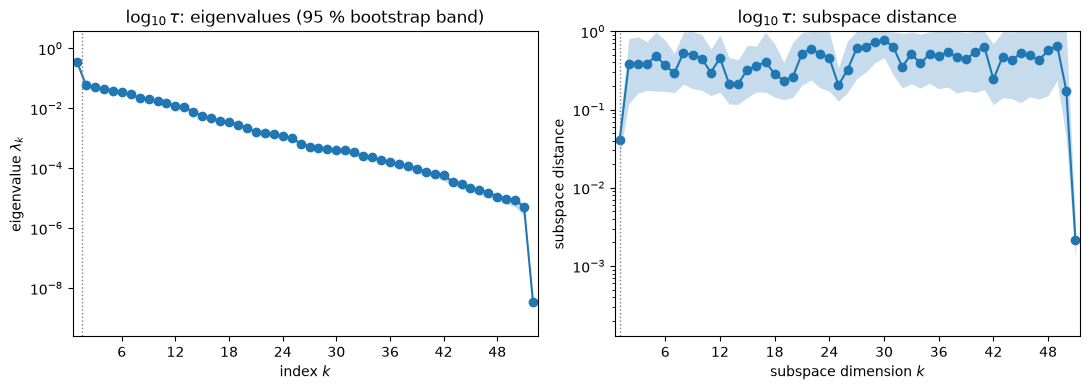

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(subI, ax=axes[0])
axes[0].set_title(r'$\log_{10}\tau$: eigenvalues (95 % bootstrap band)')
ac.plotting.plot_subspace_errors(subI, ax=axes[1])
axes[1].set_title(r'$\log_{10}\tau$: subspace distance')
fig.tight_layout(); plt.close(fig)
lam = subI.eigenvalues
print(f'lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}; '
      f'lambda_52/lambda_1 = {lam[-1] / lam[0]:.1e}')
print(f'share of the trace outside the first 1, 2, 5, 10 eigenvalues: '
      + ', '.join(f'{1 - lam[:k].sum() / lam.sum():.3f}' for k in (1, 2, 5, 10)))
fig

For $\log_{10}\tau$ the first eigenvalue stands apart, $\lambda_1/\lambda_2 = 6.14$, and there is no later gap (the next ratios are 1.13, 1.14, 1.15 and 1.11). $\lambda_1$ holds a share 0.473 of the trace; the other 0.527 is spread thinly over the remaining directions (0.106 lies outside the first ten). The first direction is well determined (mean bootstrap distance 0.041); the second is not (0.378), and the library warns that the bootstrap replicates of $\mathbf w_2$ are poorly aligned, as expected when $\lambda_2$ and $\lambda_3$ are close. The smallest eigenvalue is $9.3\times10^{-9}\lambda_1$.

**Eigenvectors.**

w1: R1 -0.444, S13 +0.411, R22L -0.372, R10 -0.318, R14 +0.283, S51 -0.210, R11 -0.199, S19 +0.176, R13 -0.168, R20 -0.147
w2: S51 +0.739, S13 -0.307, R10 -0.280, R20 -0.254, R1 -0.240, S33 +0.207, R22L +0.188, R19 -0.135
w1^2 cumulative over the largest 5, 10, 20 components: 0.685, 0.850, 0.987
   R1    H + O2 <=> O + OH
   S13   NH3 + NO <=> HNO + NH2
   R22L  H + NO (+M) <=> HNO (+M)
   R10   NH2 + O2 <=> H2NO + O
   R14   NH2 + NO <=> H2O + N2
   S51   NH2 + O2 <=> HNO + OH


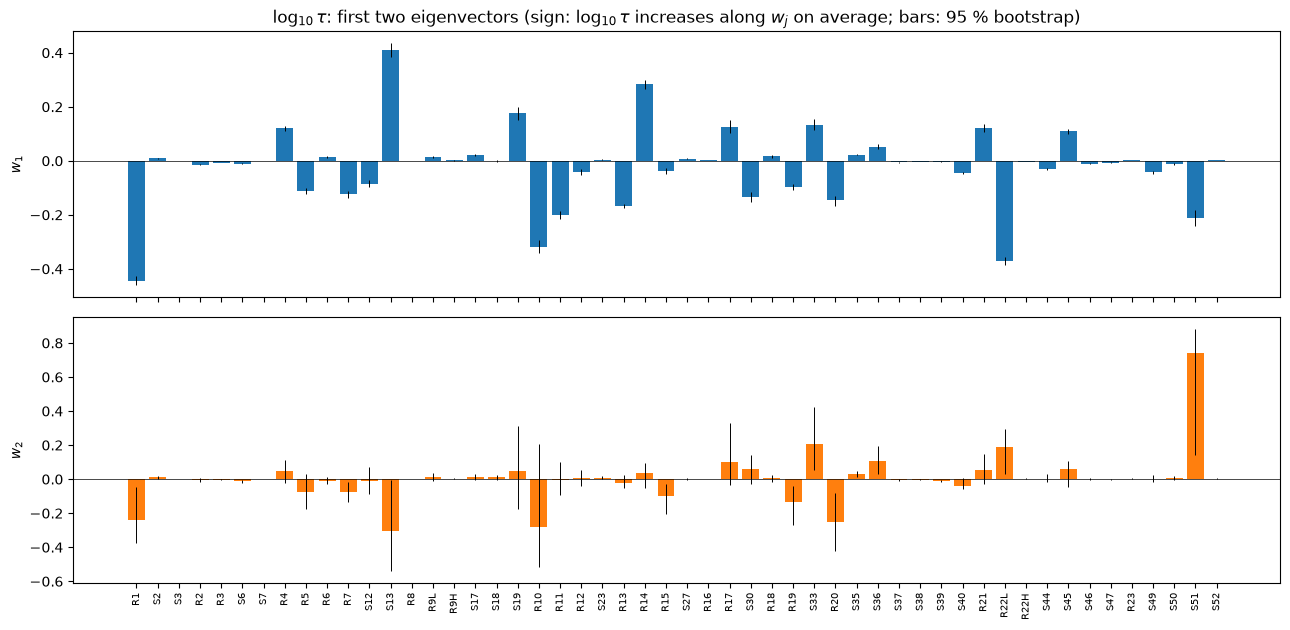

In [7]:
def bar_vectors(sub, title, k=2):
    fig, axes = plt.subplots(k, 1, figsize=(13, 3.2 * k), sharex=True)
    for j in range(k):
        w = sub.W[:, j]
        reps = sub.bootstrap_eigenvectors[:, :, j] if sub.bootstrap_eigenvectors is not None else None
        axes[j].bar(range(D.M_INPUTS), w, color=f'C{j}')
        if reps is not None:
            lo, hi = np.percentile(reps, [2.5, 97.5], axis=0)
            axes[j].errorbar(range(D.M_INPUTS), w, yerr=[w - lo, hi - w], fmt='none', ecolor='k', lw=.7)
        axes[j].axhline(0, color='k', lw=.5)
        axes[j].set_ylabel(f'$w_{{{j + 1}}}$')
    axes[0].set_title(title)
    axes[-1].set_xticks(range(D.M_INPUTS)); axes[-1].set_xticklabels(LAB, rotation=90, fontsize=7)
    fig.tight_layout(); plt.close(fig)
    return fig

def top(w, k=8):
    o = np.argsort(-np.abs(w))[:k]
    return ', '.join(f'{LAB[i]} {w[i]:+.3f}' for i in o)

fig = bar_vectors(subI, r'$\log_{10}\tau$: first two eigenvectors (sign: $\log_{10}\tau$ increases along $w_j$ on average; bars: 95 % bootstrap)')
wI = subI.W[:, 0]
print('w1:', top(wI, 10))
print('w2:', top(subI.W[:, 1], 8))
o = np.argsort(-wI**2)
print('w1^2 cumulative over the largest 5, 10, 20 components:', ', '.join(f'{np.sum(wI[o[:k]]**2):.3f}' for k in (5, 10, 20)))
for i in o[:6]:
    print(f'   {LAB[i]:5s} {D.EQUATIONS[i]}')
fig

$\log_{10}\tau$ increases along $\mathbf w_1$. Its largest components are R1 (H + O$_2$ ⇌ O + OH, −0.444), S13 (NH$_3$ + NO ⇌ HNO + NH$_2$, +0.411), R22L (H + NO (+M) ⇌ HNO (+M), low-pressure limit, −0.372), R10 (NH$_2$ + O$_2$ ⇌ H$_2$NO + O, −0.318) and R14 (NH$_2$ + NO ⇌ H$_2$O + N$_2$, +0.283). A faster chain-branching step (R1, R10) shortens the delay; a faster NH$_2$ + NO → H$_2$O + N$_2$, a chain-terminating channel, lengthens it. The direction involves many reactions: the five largest components hold 0.685 of $\|\mathbf w_1\|^2$, the ten largest 0.850 and the twenty largest 0.987. S13 and S51, two of the six largest, are among the 27 entries that are only in the supplement's table. $\mathbf w_2$ (largest component S51, NH$_2$ + O$_2$ ⇌ HNO + OH, +0.739) is not well determined and is shown for completeness.

**Sufficient summary plots and surrogates.**

LOO R^2, log10 tau, polynomial in y1 of degree 1, 2, 3: 0.7376, 0.7372, 0.7373
LOO R^2, cubic in (y1, y2): 0.7565; linear in all 52 inputs: 0.7340


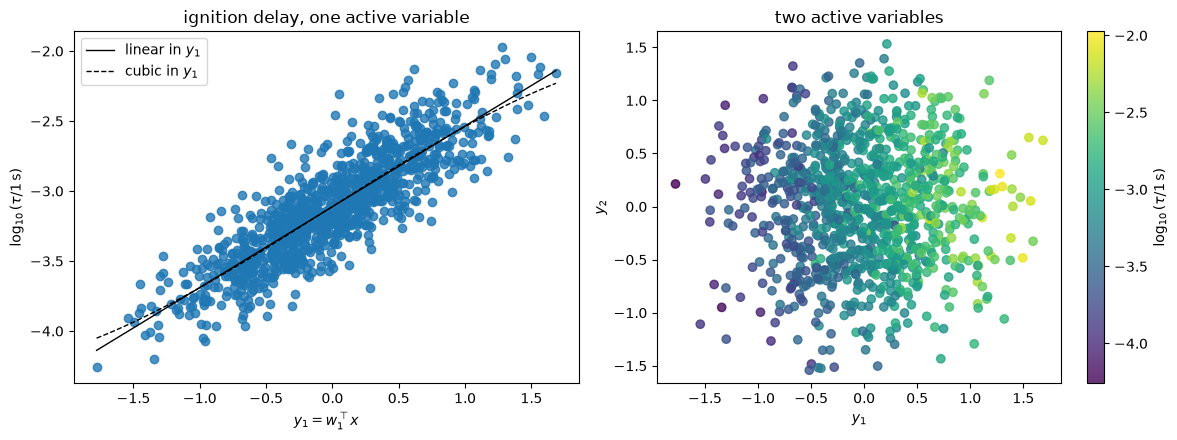

In [8]:
surI = {d: ac.fit_surrogate(X=XI, f=fI, subspace=subI, kind='poly', degree=d) for d in (1, 2, 3)}
subI2 = ac.active_subspace(space=space, X=XI, f=fI, grads=gI, estimator='as', n=2)
surI2 = ac.fit_surrogate(X=XI, f=fI, subspace=subI2, kind='poly', degree=3)
linI = ac.fit_surrogate(X=XI, f=fI, space=space, subspace=None, kind='poly', degree=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(subI, X=XI, f=fI, dims=1, qoi_label=r'$\log_{10}(\tau/1\,\mathrm{s})$', ax=axes[0])
yI = space.to_normalized(XI) @ wI
yy = np.linspace(yI.min(), yI.max(), 200)
axes[0].plot(yy, surI[1].evaluate(yy[:, None]), 'k-', lw=1, label='linear in $y_1$')
axes[0].plot(yy, surI[3].evaluate(yy[:, None]), 'k--', lw=1, label='cubic in $y_1$')
axes[0].legend(); axes[0].set_title(r'ignition delay, one active variable')
ac.plotting.plot_sufficient_summary(subI, X=XI, f=fI, dims=2, qoi_label=r'$\log_{10}(\tau/1\,\mathrm{s})$', ax=axes[1])
axes[1].set_title('two active variables')
fig.tight_layout(); plt.close(fig)
print('LOO R^2, log10 tau, polynomial in y1 of degree 1, 2, 3:', ', '.join(f'{surI[d].loo_r_squared:.4f}' for d in (1, 2, 3)))
print(f'LOO R^2, cubic in (y1, y2): {surI2.loo_r_squared:.4f}; linear in all 52 inputs: {linI.loo_r_squared:.4f}')
fig

$\log_{10}\tau$ rises almost linearly along $y_1$, with wide scatter (left). Polynomials of degree 1, 2 and 3 in $y_1$ reach leave-one-out $R^2$ = 0.7376, 0.7372 and 0.7373. A cubic in $(y_1, y_2)$ reaches 0.7565, and a linear function of all 52 inputs 0.7340. The two-variable plot (right) shows the trend along $y_1$ and little order along $y_2$. One direction carries the trend; the remaining quarter of the variance is spread over many directions, in line with the share 0.527 of the trace outside $\lambda_1$.

### Results: laminar flame speed

lambda_1/lambda_2 = 10.22, lambda_2/lambda_3 = 4.21; lambda_52/lambda_1 = 5.0e-09
share of the trace outside the first 1, 2, 5, 10 eigenvalues: 0.178, 0.098, 0.050, 0.021


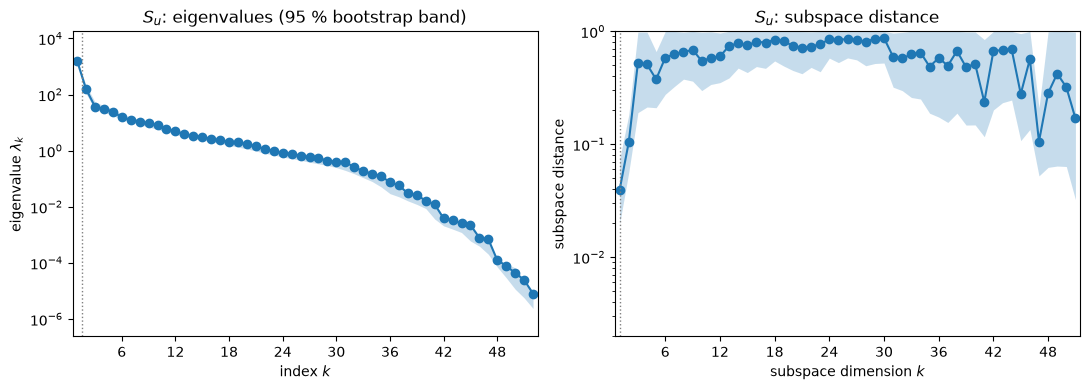

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(subL, ax=axes[0])
axes[0].set_title(r'$S_u$: eigenvalues (95 % bootstrap band)')
ac.plotting.plot_subspace_errors(subL, ax=axes[1])
axes[1].set_title(r'$S_u$: subspace distance')
fig.tight_layout(); plt.close(fig)
lam = subL.eigenvalues
print(f'lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}; '
      f'lambda_52/lambda_1 = {lam[-1] / lam[0]:.1e}')
print(f'share of the trace outside the first 1, 2, 5, 10 eigenvalues: '
      + ', '.join(f'{1 - lam[:k].sum() / lam.sum():.3f}' for k in (1, 2, 5, 10)))
fig

For $S_u$ there are two gaps: $\lambda_1/\lambda_2 = 10.22$ and $\lambda_2/\lambda_3 = 4.21$. $\lambda_1$ holds a share 0.822 of the trace and the first two 0.902; 0.050 lies outside the first five and 0.021 outside the first ten. The first two subspaces are well determined (mean bootstrap distance 0.04 for $k = 1$ and 0.105 for $k = 2$); for $k = 3$ the distance jumps to 0.526. The smallest eigenvalue is $5.0\times10^{-9}\lambda_1$.

w1: R1 +0.923, S19 -0.216, R5 +0.121, R2 +0.119, R15 +0.099, R9L -0.099, R13 +0.098, S2 -0.098, R3 +0.096, S18 -0.075
w2: S19 -0.944, R1 -0.231, S17 +0.110, R2 +0.095, R22L -0.091, R13 +0.085, R9L +0.062, S18 +0.061
w1^2 cumulative over the largest 5, 10, 20 components: 0.937, 0.981, 0.998
   R1    H + O2 <=> O + OH
   S19   NH2 + O <=> H2 + NO
   R5    NH3 + O <=> NH2 + OH
   R2    H2 + O <=> OH + H
   R15   NH2 + NH <=> N2H2 + H
   R9L   NH2 + H (+M) <=> NH3 (+M) low
|w1(log10 tau) . w1(Su)| = 0.501


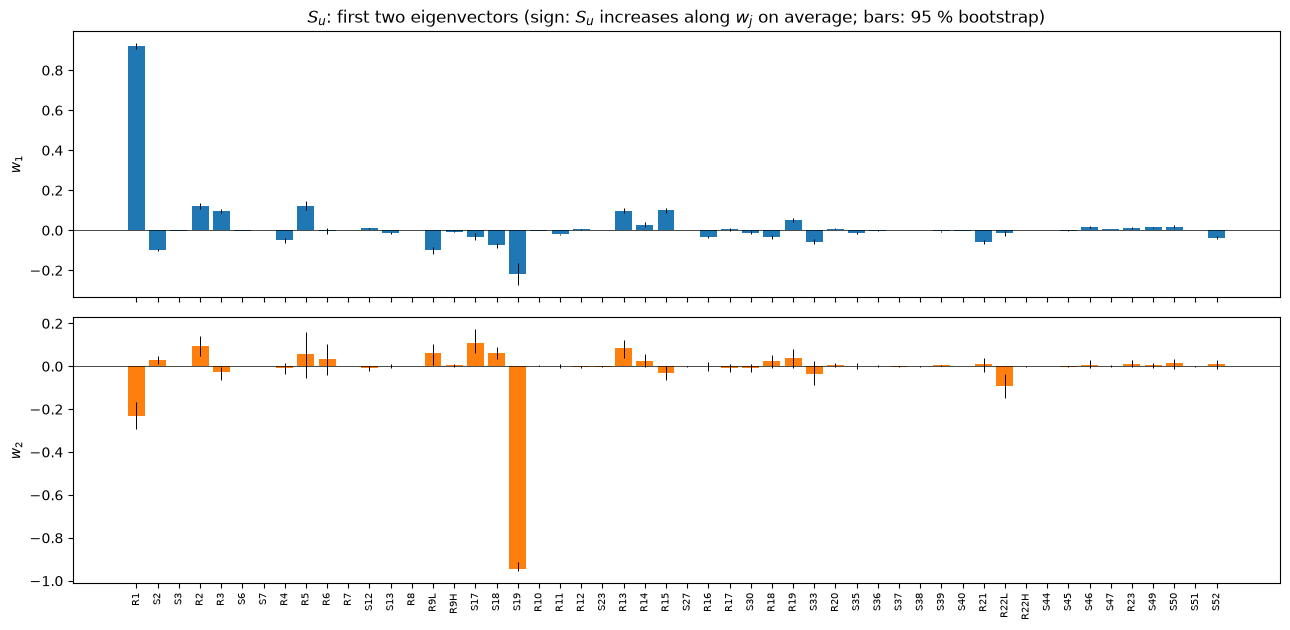

In [10]:
fig = bar_vectors(subL, r'$S_u$: first two eigenvectors (sign: $S_u$ increases along $w_j$ on average; bars: 95 % bootstrap)')
wL = subL.W[:, 0]
print('w1:', top(wL, 10))
print('w2:', top(subL.W[:, 1], 8))
o = np.argsort(-wL**2)
print('w1^2 cumulative over the largest 5, 10, 20 components:', ', '.join(f'{np.sum(wL[o[:k]]**2):.3f}' for k in (5, 10, 20)))
for i in o[:6]:
    print(f'   {LAB[i]:5s} {D.EQUATIONS[i]}')
print(f'|w1(log10 tau) . w1(Su)| = {abs(wI @ wL):.3f}')
fig

$S_u$ increases along $\mathbf w_1$, which is dominated by R1 (H + O$_2$ ⇌ O + OH, +0.923): faster chain branching speeds the flame. The next components are S19 (NH$_2$ + O ⇌ H$_2$ + NO, −0.216), R5 (NH$_3$ + O ⇌ NH$_2$ + OH, +0.121), R2 (H$_2$ + O ⇌ OH + H, +0.119) and R15 (NH$_2$ + NH ⇌ N$_2$H$_2$ + H, +0.099); the five largest components hold 0.937 of $\|\mathbf w_1\|^2$. $\mathbf w_2$ is almost S19 alone (−0.944, with R1 at −0.231). The flame and ignition directions differ: $|\mathbf w_1(\log_{10}\tau)\cdot\mathbf w_1(S_u)| = 0.501$. R1 leads both, but the ignition direction is shared among NH$_x$/NO reactions that barely move the flame.

LOO R^2, Su, polynomial in y1 of degree 1, 2, 3: 0.8820, 0.9332, 0.9324
LOO R^2, cubic in (y1, y2): 0.9440; linear in all 52 inputs: 0.8460


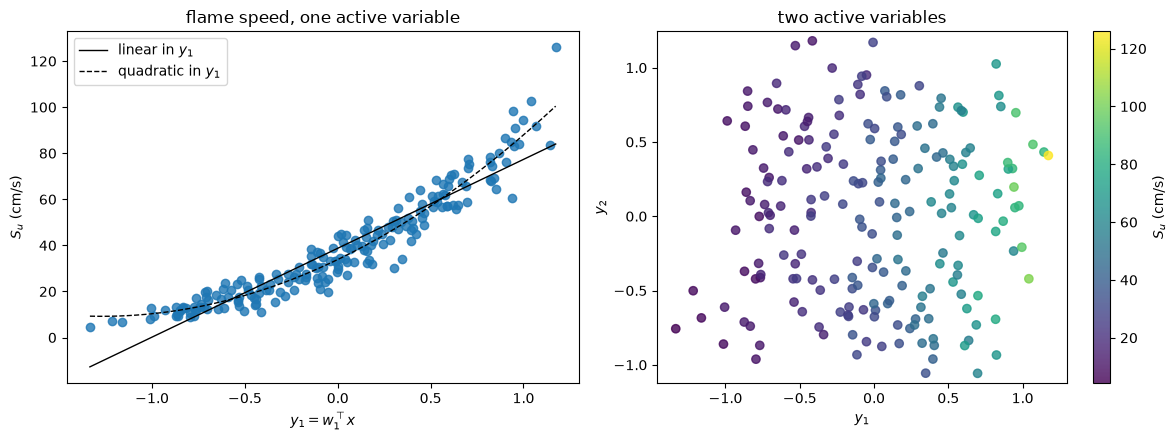

In [11]:
surL = {d: ac.fit_surrogate(X=XL, f=fL, subspace=subL, kind='poly', degree=d) for d in (1, 2, 3)}
subL2 = ac.active_subspace(space=space, X=XL, f=fL, grads=gL, estimator='as', n=2)
surL2 = ac.fit_surrogate(X=XL, f=fL, subspace=subL2, kind='poly', degree=3)
linL = ac.fit_surrogate(X=XL, f=fL, space=space, subspace=None, kind='poly', degree=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(subL, X=XL, f=fL, dims=1, qoi_label=r'$S_u$ (cm/s)', ax=axes[0])
yL = space.to_normalized(XL) @ wL
yy = np.linspace(yL.min(), yL.max(), 200)
axes[0].plot(yy, surL[1].evaluate(yy[:, None]), 'k-', lw=1, label='linear in $y_1$')
axes[0].plot(yy, surL[2].evaluate(yy[:, None]), 'k--', lw=1, label='quadratic in $y_1$')
axes[0].legend(); axes[0].set_title('flame speed, one active variable')
ac.plotting.plot_sufficient_summary(subL, X=XL, f=fL, dims=2, qoi_label=r'$S_u$ (cm/s)', ax=axes[1])
axes[1].set_title('two active variables')
fig.tight_layout(); plt.close(fig)
print('LOO R^2, Su, polynomial in y1 of degree 1, 2, 3:', ', '.join(f'{surL[d].loo_r_squared:.4f}' for d in (1, 2, 3)))
print(f'LOO R^2, cubic in (y1, y2): {surL2.loo_r_squared:.4f}; linear in all 52 inputs: {linL.loo_r_squared:.4f}')
fig

$S_u$ is a convex function of $y_1$ with modest scatter (left). Leave-one-out $R^2$ is 0.8820 (linear in $y_1$), 0.9332 (quadratic) and 0.9324 (cubic); a cubic in $(y_1, y_2)$ reaches 0.9440, and a linear function of all 52 inputs 0.8460. So a quadratic in one active variable describes the flame speed better than a linear model in all 52 inputs. The quadratic flattens at the left end of the data, where samples are few, and should not be extrapolated.

**Size of the flame-speed gradients.** `check_accuracy.py` (check 6) compares the adjoint with central differences on the same grid at 21 flames across the design (ranks 0, 10, ..., 190 and 199 of $S_u$). The adjoint gradients point the right way, but they are too short by a factor that grows as the flame slows. The cell below holds the 21 measured ratios (adjoint / differences, along the adjoint direction), fits $1 - r = a\,S_u^{b}$, divides every stored gradient by the fitted ratio $r$, and recomputes the subspace.

In [12]:
S_CHK = np.array([4.4149, 10.8227, 12.4709, 14.4657, 17.2664, 19.1937, 22.4493, 25.5708, 27.5841, 31.0892, 33.8240,
                  38.2603, 41.7785, 45.1434, 48.9147, 55.6640, 59.0299, 65.7940, 71.1439, 83.6044, 125.9824])   # Su, cm/s
R_CHK = np.array([0.8394, 0.9493, 0.9364, 0.9567, 0.9485, 0.9561, 0.9816, 0.9802, 0.9792, 0.9801, 0.9678,
                  0.9913, 0.9826, 0.9931, 0.9854, 0.9922, 0.9934, 0.9953, 0.9945, 0.9978, 0.9957])        # adjoint / differences
print(f'measured (check 6): shortfall 1 - r from {1 - R_CHK.max():.3f} to {1 - R_CHK.min():.3f} (Su = {S_CHK[np.argmin(R_CHK)]:.2f} cm/s); '
      f'{1 - R_CHK[10]:.3f} at Su = {S_CHK[10]:.2f} cm/s (median of the design {np.median(fL):.2f}); '
      f'mean {np.mean(1 - R_CHK[S_CHK > 50]):.3f} above 50 cm/s')
B_FIT, lnA = np.polyfit(np.log(S_CHK), np.log(1 - R_CHK), 1)
A_FIT = np.exp(lnA)
ratio = 1.0 - A_FIT * fL**B_FIT
print(f'fit 1 - r = {A_FIT:.3f} Su^{B_FIT:.3f}; over the {len(fL)} flames the fitted shortfall runs from {1 - ratio.max():.3f} to '
      f'{1 - ratio.min():.3f} (median {np.median(1 - ratio):.3f}); share more than 1, 3, 5 % short: '
      f'{np.mean(1 - ratio > 0.01):.2f}, {np.mean(1 - ratio > 0.03):.2f}, {np.mean(1 - ratio > 0.05):.2f}')
subLc = ac.active_subspace(space=space, X=XL, f=fL, grads=gL / ratio[:, None], estimator='as')
lc, l0 = subLc.eigenvalues, subL.eigenvalues
Wc = subLc.W
P0, Pc = subL.W[:, :2] @ subL.W[:, :2].T, Wc[:, :2] @ Wc[:, :2].T
print(f'stored gradients:    lambda1/lambda2 = {l0[0] / l0[1]:.3f}, lambda2/lambda3 = {l0[1] / l0[2]:.3f}')
print(f'rescaled gradients:  lambda1/lambda2 = {lc[0] / lc[1]:.3f}, lambda2/lambda3 = {lc[1] / lc[2]:.3f}; lambda1 x {lc[0] / l0[0]:.4f}')
print(f'|w1 . w1\'| = {abs(subL.W[:, 0] @ Wc[:, 0]):.5f}, |w2 . w2\'| = {abs(subL.W[:, 1] @ Wc[:, 1]):.5f}, '
      f'distance of the 2-d subspaces {np.linalg.norm(P0 - Pc, 2):.4f}')

measured (check 6): shortfall 1 - r from 0.002 to 0.161 (Su = 4.41 cm/s); 0.032 at Su = 33.82 cm/s (median of the design 33.59); mean 0.005 above 50 cm/s
fit 1 - r = 1.390 Su^-1.283; over the 200 flames the fitted shortfall runs from 0.003 to 0.207 (median 0.015); share more than 1, 3, 5 % short: 0.67, 0.26, 0.14
stored gradients:    lambda1/lambda2 = 10.218, lambda2/lambda3 = 4.209
rescaled gradients:  lambda1/lambda2 = 10.223, lambda2/lambda3 = 4.216; lambda1 x 1.0259
|w1 . w1'| = 1.00000, |w2 . w2'| = 1.00000, distance of the 2-d subspaces 0.0021


The measured shortfall runs from 0.002 to 0.161, largest at the slowest flame (4.41 cm/s); it is 0.032 at 33.82 cm/s, next to the design's median of 33.59 cm/s, and 0.005 on average above 50 cm/s. The fit $1 - r = 1.390\,S_u^{-1.283}$ puts 67 % of the flames more than 1 % short, 26 % more than 3 % and 14 % more than 5 % (it overstates the slowest flame: 0.207 against the measured 0.161). Correcting the sizes changes $\lambda_1/\lambda_2$ from 10.218 to 10.223 and $\lambda_2/\lambda_3$ from 4.209 to 4.216, multiplies $\lambda_1$ by 1.0259, and leaves the eigenvectors in place ($|\mathbf w_1\cdot\mathbf w_1'| = |\mathbf w_2\cdot\mathbf w_2'| = 1.00000$; distance of the two-dimensional subspaces 0.0021). The bias in the adjoint moves the eigenvalues by a few per cent and does not change the active directions, the dimension choice or the sufficient summary plots, which use $\mathbf W$ only.

### Choice of dimension

**Ignition delay: $n = 1$.** The only gap is after $\lambda_1$ ($\lambda_1/\lambda_2 = 6.14$; the next ratios are 1.11–1.15), $\mathbf w_1$ is well determined (distance 0.041) while $\mathbf w_2$ is not (0.378), and adding $y_2$ raises the leave-one-out $R^2$ only from 0.7373 (cubic in $y_1$) to 0.7565. The cost is that a share 0.527 of the trace, and about a quarter of the variance of $\log_{10}\tau$, stay outside the subspace; a larger $n$ would not change that much, since no later gap exists. The library's gap rule also picks $n = 1$.

**Flame speed: $n = 1$** for the headline, the gap rule's choice: $\lambda_1/\lambda_2 = 10.22$, $\lambda_1$ holds a share 0.822 of the trace, and a quadratic in $y_1$ has leave-one-out $R^2$ = 0.9332. $n = 2$ is also defensible: $\lambda_2/\lambda_3 = 4.21$ is a second, smaller gap, $\mathbf w_2$ is well determined (distance 0.105), and a cubic in $(y_1, y_2)$ reaches 0.9440.

### The reduced bounds seen along the active direction

The paper's result is a set of reduced bounds: each factor moves from $[-f^{ini}_i, f^{ini}_i]$ to $[-f^{red}_{l,i}, f^{red}_{u,i}]$ [1, Sec. 3.4, p. 10; supplement table], and, after showing the samples of R4, R13 and R18 in Fig. 10(a), the paper says that "for reactions other than these three, the width of the reduced bounds is approximately 0.2–0.3 times that of the initial bounds" (p. 10). In the supplement's table the ratio of widths runs from 0.221 to 0.288 for all 52 entries, these three included (printed with the input table). Along an active direction the reduced box spans a shorter interval of $y_1$, and the one-dimensional surrogates (cubic for $\log_{10}\tau$, quadratic for $S_u$) give a quick estimate of the spread of the predictions. For most entries, however, the reduced box carries little information from the experiments: 41 of the 52 reduced widths lie between 0.2800 and 0.2881, just under 0.2887, the $\pm 0.5\sigma$ width of the unfiltered log-uniform prior (printed with the input table), so the shrink factors below mostly reflect the $\pm 0.5\sigma$ rule itself. The informative part is which entries the filtering narrowed further, and we compare those with the active directions. We sample both boxes uniformly (20 000 points each, seed `SEED`) and evaluate the surrogates. The surrogates are used inside the range they were fitted on, but they ignore the variation outside the active subspace, which is large for $\log_{10}\tau$; this is our illustration, not a computation of the paper.

In [13]:
rng = np.random.default_rng(SEED)
lo_red, up_red = -D.F_RED_L / D.F_INI, D.F_RED_U / D.F_INI     # the reduced box in normalized coordinates
Zr = lo_red + (up_red - lo_red) * rng.random((20000, D.M_INPUTS))
Zi = -1 + 2 * rng.random((20000, D.M_INPUTS))
for name, w, sur in [('log10 tau', wI, surI[3]), ('Su', wL, surL[2])]:
    ext_i = np.sum(np.abs(w))
    ext_r = (np.sum(np.where(w > 0, w * up_red, w * lo_red)), np.sum(np.where(w > 0, w * lo_red, w * up_red)))
    yi, yr = Zi @ w, Zr @ w
    pi_, pr_ = sur.evaluate(yi[:, None]), sur.evaluate(yr[:, None])
    print(f'{name:9s}: y1 over the initial box [{-ext_i:.3f}, {ext_i:.3f}], over the reduced box [{ext_r[1]:.3f}, {ext_r[0]:.3f}]; '
          f'sd of y1 under uniform sampling {yi.std():.3f} (initial) and {yr.std():.3f} (reduced), ratio {yr.std() / yi.std():.3f}')
    print(f'           surrogate in y1: 2.5-97.5 % range {np.percentile(pi_, 2.5):.3f} to {np.percentile(pi_, 97.5):.3f} (initial), '
          f'{np.percentile(pr_, 2.5):.3f} to {np.percentile(pr_, 97.5):.3f} (reduced); mean {pi_.mean():.3f} and {pr_.mean():.3f}')
    r95 = np.diff(np.percentile(pr_, [2.5, 97.5]))[0] / np.diff(np.percentile(pi_, [2.5, 97.5]))[0]
    print(f'           ratio of the 95 % ranges, reduced / initial: {r95:.3f}')
narrow = np.nonzero(r_red < 0.279)[0]
narrow = narrow[np.argsort(r_red[narrow])]
imp = wI**2 + wL**2                                          # weight of each input in the two first eigenvectors
gap = 1 / np.sqrt(12) - r_red                                # narrowing beyond the +/- 0.5 sd rule
rk = lambda v: np.argsort(np.argsort(v)).astype(float)
top10 = np.argsort(-imp)[:10]
print(f'entries narrowed below 0.279: ' + ', '.join(f'{LAB[i]} {r_red[i]:.3f}' for i in narrow))
print(f'ten largest w1(log10 tau)^2 + w1(Su)^2: ' + ', '.join(LAB[i] for i in top10)
      + f'; of these, {np.sum(np.isin(top10, narrow))} are among the narrowed entries')
print(f'correlation of 0.2887 - width ratio with w1(log10 tau)^2 + w1(Su)^2: Spearman {np.corrcoef(rk(gap), rk(imp))[0, 1]:.2f}, '
      f'Pearson {np.corrcoef(gap, imp)[0, 1]:.2f} (without R1: {np.corrcoef(gap[1:], imp[1:])[0, 1]:.2f})')


log10 tau: y1 over the initial box [-4.347, 4.347], over the reduced box [-1.215, 1.164]; sd of y1 under uniform sampling 0.577 (initial) and 0.155 (reduced), ratio 0.268
           surrogate in y1: 2.5-97.5 % range -3.749 to -2.478 (initial), -3.309 to -2.946 (reduced); mean -3.112 and -3.126
           ratio of the 95 % ranges, reduced / initial: 0.286
Su       : y1 over the initial box [-2.521, 2.521], over the reduced box [-0.609, 0.699]; sd of y1 under uniform sampling 0.579 (initial) and 0.133 (reduced), ratio 0.229
           surrogate in y1: 2.5-97.5 % range 10.009 to 89.930 (initial), 26.830 to 46.300 (reduced); mean 38.933 and 35.925
           ratio of the 95 % ranges, reduced / initial: 0.244
entries narrowed below 0.279: R1 0.221, R14 0.268, R22L 0.275, R15 0.275, R7 0.276, R10 0.276, R6 0.276, R5 0.277, S30 0.278, R11 0.278
ten largest w1(log10 tau)^2 + w1(Su)^2: R1, S13, R22L, R10, R14, S19, S51, R11, R13, R5; of these, 6 are among the narrowed entries
correlation of 0.2

Under uniform sampling the standard deviation of $y_1$ falls to 0.268 ($\log_{10}\tau$) and 0.229 ($S_u$) of its value on the initial box, and the surrogates' 95 % ranges shrink by similar factors, 0.286 and 0.244: from $[-3.749, -2.478]$ to $[-3.309, -2.946]$ in $\log_{10}(\tau/1\,\mathrm s)$, and from 10.009–89.930 to 26.830–46.300 cm/s in $S_u$ (mean 38.933 and 35.925 cm/s). Because the active directions are spread over many inputs, each narrowed by a similar factor, the spread along $y_1$ shrinks by about the per-input factor. The paper's Fig. 10(b) and (c) (p. 11) show the corresponding narrowing of its Monte Carlo predictions. Most of this narrowing is the $\pm 0.5\sigma$ rule applied to an unconstrained prior; the ten entries the filtering narrowed below a ratio of 0.279 (R1 0.221, R14 0.268, R22L 0.275, then R15, R7, R10, R6, R5, S30 and R11) include six of the ten inputs with the largest weight $w_1(\log_{10}\tau)^2 + w_1(S_u)^2$ (R1, R22L, R10, R14, R11, R5), and the narrowing beyond 0.2887 correlates with that weight (Spearman 0.60, Pearson 0.93, 0.54 without R1). The reactions the experiments constrained tend to be the ones the active directions weight most, an independent agreement between the paper's filtering and the gradients computed here.

### Comparison with the paper

The paper does not compute active subspaces, so there is no published subspace to match. The table compares what can be compared: the setting, the nominal model and the spread under the initial bounds (read from the paper's Fig. 10), and the importance ranking.

In [14]:
rank = lambda w, i: int(np.where(np.argsort(-np.abs(w)) == i)[0][0]) + 1
print(f'nominal model: tau = {nom[0, 0] * 1e3:.3f} ms, Su = {nom[1, 0]:.2f} cm/s')
print(f'design: tau from {taui[ok_i].min() * 1e3:.3f} to {taui[ok_i].max() * 1e3:.2f} ms; Su from {fL.min():.2f} to {fL.max():.2f} cm/s')
print(f'samples with tau in [0.1, 10] ms: {np.mean((taui[ok_i] >= 1e-4) & (taui[ok_i] <= 1e-2)):.3f}; '
      f'flames with Su > 70 cm/s: {np.sum(fL > 70)} of {len(fL)}')
print(f'rank of R1 (H + O2 <=> O + OH) by |w1|: {rank(wI, 0)} (log10 tau), {rank(wL, 0)} (Su); '
      f'|w1| of R1: {abs(wI[0]):.3f}, {abs(wL[0]):.3f}')
for name, s in [('log10 tau', subI), ('Su', subL)]:
    lam = s.eigenvalues
    print(f'{name:9s}: lambda1/lambda2 {lam[0] / lam[1]:.2f}, lambda2/lambda3 {lam[1] / lam[2]:.2f}')

nominal model: tau = 0.691 ms, Su = 40.69 cm/s
design: tau from 0.055 to 10.63 ms; Su from 4.41 to 125.98 cm/s
samples with tau in [0.1, 10] ms: 0.992; flames with Su > 70 cm/s: 21 of 200
rank of R1 (H + O2 <=> O + OH) by |w1|: 1 (log10 tau), 1 (Su); |w1| of R1: 0.444, 0.923
log10 tau: lambda1/lambda2 6.14, lambda2/lambda3 1.13
Su       : lambda1/lambda2 10.22, lambda2/lambda3 4.21


| Quantity | Paper value | Notebook value |
|---|---|---|
| Mechanism and solver | 42 species, 346 reactions [1, p. 5]; Cantera [1, p. 3] | the supplement's `NH3_H2.yaml`, Cantera 3.2.0 |
| Uncertain inputs | $A$ of 52 reactions, falloff limits counted separately (pp. 5, 9); bounds as factors (Eqs. 5–6) | 52 inputs $x_i = \log_{10}(A_i/A_{i,0})$, uniform on $[-f^{ini}_i, f^{ini}_i]$ (supplement table) |
| Design | Latin hypercube, 100,000 samples (p. 9); 30–50 per condition (p. 3) | Latin hypercubes of 1000 ($\tau$) and 200 ($S_u$) samples, with gradients |
| $\tau$, nominal model, 10 atm, $T_5$ = 1587.98 K | not reported; the simulation line of Fig. 10(b) is a little below 1 ms there (read from the figure); measured 0.4 ms (Chen et al. [3], supplement) | 0.691 ms |
| Spread of $\tau$ under the initial bounds | Fig. 10(b): points between about $10^{-4}$ and $10^{-2}$ s near this temperature (read from the figure) | 0.055–10.63 ms; a fraction 0.992 of the samples in [0.1, 10] ms |
| $S_u$, nominal model, $\phi$ = 1 | not reported; about 40–45 cm/s on the simulation line of Fig. 10(c) (read from the figure); measured 35.656, 48.85 and 45.75 cm/s (supplement: Mei 2021, Lhuillier 2020, Li 2014) | 40.69 cm/s (on a coarser grid than the paper's; `DATA.md`) |
| Spread of $S_u$ under the initial bounds | Fig. 10(c): points from near 0 up to the axis limit, 70 cm/s, near $\phi$ = 1 | 4.41–125.98 cm/s; 21 of 200 flames above 70 cm/s |
| Most important reaction | R1, H + O$_2$ ⇌ O + OH: largest overall sensitivity coefficient in all 11 models (Fig. 3, p. 6) and "the most sensitive" in Fig. 2(a) (p. 4) | R1 is the largest component of $\mathbf w_1$ for both quantities (0.444 and 0.923) |
| Narrowing by the reduced bounds | widths about 0.2–0.3 of the initial ones (p. 10); narrower Monte Carlo bands in Fig. 10(b), (c) | spread along $y_1$: ratio 0.268 ($\log_{10}\tau$), 0.229 ($S_u$); surrogate 95 % ranges: 0.286, 0.244 |
| Entries narrowed most by the filtering | reduced widths in the supplement's table; most are 0.280–0.288 of the initial width, the narrowest R1 (0.221), R14, R22L | six of the ten narrowed entries are among the ten largest $w_1(\log_{10}\tau)^2 + w_1(S_u)^2$; correlation of the narrowing with that weight 0.60 (Spearman), 0.93 (Pearson) |
| Active subspace | not computed | $\log_{10}\tau$: $\lambda_1/\lambda_2$ = 6.14, $n$ = 1, LOO $R^2$ 0.7376; $S_u$: $\lambda_1/\lambda_2$ = 10.22, $\lambda_2/\lambda_3$ = 4.21, $n$ = 1, LOO $R^2$ 0.9332 (quadratic) |

The two quantities agree with the paper where it gives something to compare: the same leading reaction, a nominal ignition delay and flame speed close to the simulation lines of Fig. 10, and a spread under the initial bounds of about two decades in $\tau$. Our flame-speed spread reaches higher than the figure shows (21 of 200 flames above its 70 cm/s axis limit); the paper ran 30–50 random models per condition, and its plotted points may not cover the tails. The active subspaces themselves are new.

### References

[1] G. Huang, H. Wang, L. Tian, O. Haidn, and N. Slavinskaya. [Uncertainty quantification and reduction for combustion kinetic Modeling: A case study of NH$_3$/H$_2$ models](https://doi.org/10.1016/j.fuel.2025.135810). *Fuel*, 400:135810, 2025. Supplementary data (Appendix A): the mechanism (Cantera and Chemkin formats), the table of the 52 reactions with their uncertainty factors, and the experimental data.

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, Philadelphia, 2015.

[3] J. Chen, X. Jiang, X. Qin, and Z. Huang. [Effect of hydrogen blending on the high temperature auto-ignition of ammonia at elevated pressure](https://doi.org/10.1016/j.fuel.2020.119563). *Fuel*, 287:119563, 2021. (Source of the shock-tube condition used for $\tau$, through the supplement of [1].)

[4] D. G. Goodwin, H. K. Moffat, I. Schoegl, R. L. Speth, and B. W. Weber. Cantera: an object-oriented software toolkit for chemical kinetics, thermodynamics, and transport processes. Version 3.2.0, https://www.cantera.org.

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 6.9 s
